<a href="https://colab.research.google.com/github/othmane71-art/ai-soc-traffic-anomaly-detection/blob/main/regression_rineaire_trafic_reseau_fictif.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [ ]:
data = {
    "utilisateurs": [10, 15, 20, 25, 30, 35, 40, 45, 50, 55,
                     60, 65, 70, 75, 80, 85, 90, 95, 100, 105],
    "trafic": [20, 27, 35, 43, 50, 57, 66, 72, 80, 88,
               95, 103, 110, 118, 125, 133, 140, 149, 155, 165]
}
df = pd.DataFrame(data)
display(df)

,utilisateurs,trafic
0,10,20
1,15,27
2,20,35
3,25,43
4,30,50
5,35,57
6,40,66
7,45,72
8,50,80
9,55,88


Logique métier : ces données simulent une télémétrie légitime (sessions actives contre débit en Mbps), comme on l'extrairait d'un pare-feu ou d'un NetFlow. Un modèle de détection doit apprendre sur du trafic supposé sain. Dans la vraie vie, il faut donc vérifier que les données d'entraînement ne contiennent pas déjà d'attaque (data poisoning).

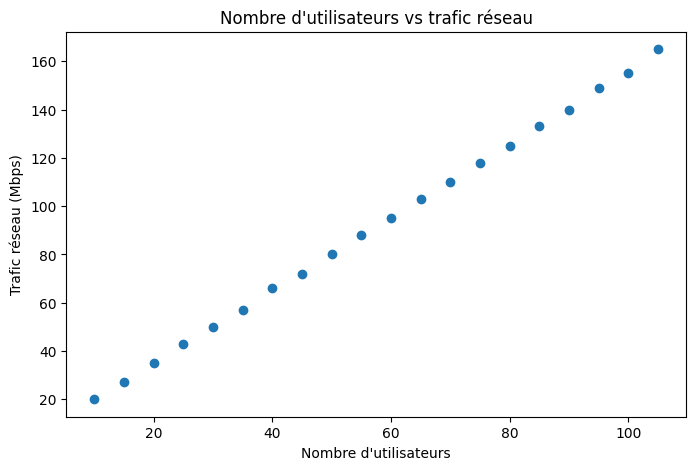

In [ ]:
plt.figure(figsize=(8,5))
plt.scatter(df["utilisateurs"], df["trafic"])
plt.xlabel("Nombre d'utilisateurs")
plt.ylabel("Trafic réseau (Mbps)")
plt.title("Nombre d'utilisateurs vs trafic réseau")
plt.show()

In [ ]:
X = df[["utilisateurs"]]
y = df["trafic"]

display(X.head())
display(y.head())

,utilisateurs
0,10
1,15
2,20
3,25
4,30


,trafic
0,20
1,27
2,35
3,43
4,50


Logique métier : X est la cause observable, la charge utilisateur. y est ce qu'on veut prédire, le débit attendu. Les doubles crochets [[ ]] créent un DataFrame 2D, que scikit-learn exige pour X. Ensuite, toute variable ajoutée (heure, nombre de connexions, ports) viendra enrichir X sans changer le reste du code.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

print("Données d'entraînement :", len(X_train))
print("Données de test :", len(X_test))

Données d'entraînement : 16
Données de test : 4


Logique métier : le modèle apprend sur 80% des données. Les 20% restants simulent du trafic jamais vu, pour mesurer sa capacité de généralisation. C'est le même principe qu'un test d'une règle de détection sur des logs qui n'ont pas servi à l'écrire.

In [ ]:
model = LinearRegression()
model.fit(X_train, y_train)

print("Modèle entraîné.")

Modèle entraîné.


_Logique métier : `fit()` calcule la droite qui minimise la somme des carrés des écarts (moindres carrés). Cette droite devient la baseline de trafic normal._

In [ ]:
beta0 = model.intercept_
beta1 = model.coef_[0]

print("β0 (intercept) =", beta0)
print("β1 (pente) =", beta1)
print(f"Équation : ŷ = {beta0:.2f} + {beta1:.2f}x")

β0 (intercept) = 4.672900015080685
β1 (pente) = 1.5103001055647716
Équation : ŷ = 4.67 + 1.51x


Logique métier :

β₁ est le débit moyen ajouté par utilisateur supplémentaire, en Mbps par utilisateur. Un utilisateur qui consomme bien plus que cette valeur est un point à surveiller (exfiltration, téléchargement massif).

β₀ est le trafic de base quand le nombre d'utilisateurs tend vers 0 : services système, sauvegardes, supervision. Attention, il n'a de sens que dans la plage observée (10 à 105 utilisateurs).

In [ ]:
y_pred = model.predict(X_test)

resultats = pd.DataFrame({
    "Utilisateurs": X_test["utilisateurs"].values,
    "Trafic réel": y_test.values,
    "Trafic prédit": y_pred
})

display(resultats)

,Utilisateurs,Trafic réel,Trafic prédit
0,10,20,19.775901
1,95,149,148.151410
2,85,133,133.048409
3,15,27,27.327402


on demande au modèle le trafic attendu sur 4 cas qu'il n'a jamais vus, puis on le compare au trafic réel. C'est l'équivalent d'un test de la baseline sur des données hors entraînement.

In [ ]:
resultats["Résidu"] = (
    resultats["Trafic réel"] - resultats["Trafic prédit"]
)

display(resultats)

,Utilisateurs,Trafic réel,Trafic prédit,Résidu
0,10,20,19.775901,0.224099
1,95,149,148.151410,0.848590
2,85,133,133.048409,-0.048409
3,15,27,27.327402,-0.327402


le résidu e = y − ŷ est ton score d'anomalie brut. Un résidu positif signifie plus de trafic que prévu (exfiltration, scan, DDoS entrant). Un résidu négatif signifie moins de trafic que prévu (service tombé, lien coupé, collecte de logs en panne). Les deux cas méritent un regard.

In [ ]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("MAE :", mae)
print("MSE :", mse)
print("R² :", r2)

MAE : 0.36212486804404787
MSE : 0.21996512020959738
R² : 0.9999369671008623


- MAE : l'erreur moyenne en Mbps. Elle sert à fixer un seuil d'alerte réaliste.

- MSE : l'erreur élevée au carré, qui pénalise fortement les gros écarts. Elle est utile pour détecter les pics.

- R² : la part de variation du trafic expliquée par le nombre d'utilisateurs. Un R² proche de 1 signifie que la baseline est fiable.

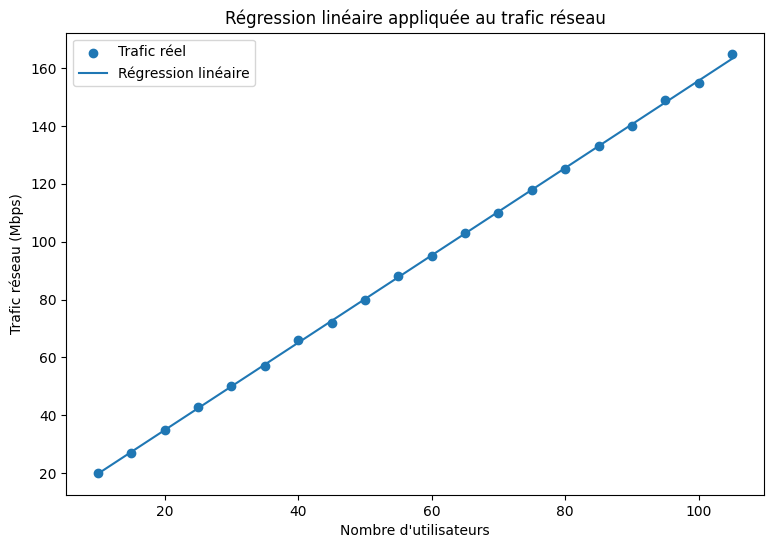

In [ ]:
X_plot = pd.DataFrame({
    "utilisateurs": np.linspace(
        df["utilisateurs"].min(),
        df["utilisateurs"].max(),
        100
    )
})

y_plot = model.predict(X_plot)

plt.figure(figsize=(9,6))
plt.scatter(df["utilisateurs"], df["trafic"], label="Trafic réel")
plt.plot(X_plot["utilisateurs"], y_plot, label="Régression linéaire")
plt.xlabel("Nombre d'utilisateurs")
plt.ylabel("Trafic réseau (Mbps)")
plt.title("Régression linéaire appliquée au trafic réseau")
plt.legend()
plt.show()

In [ ]:
nouvelle_donnee = pd.DataFrame({
    "utilisateurs": [110]
})

trafic_attendu = model.predict(nouvelle_donnee)[0]

print(
    f"Pour 110 utilisateurs, le trafic attendu est "
    f"{trafic_attendu:.2f} Mbps."
)

Pour 110 utilisateurs, le trafic attendu est 170.81 Mbps.


Logique métier : 110 est hors de la plage d'entraînement (10 à 105). C'est de l'extrapolation, valable ici car la relation est linéaire. Sur un vrai réseau, elle peut être fausse (saturation de bande passante, QoS). Cette prédiction sert de baseline pour la cellule suivante.

In [ ]:
trafic_observe = 220
residu = trafic_observe - trafic_attendu

print("Trafic attendu :", round(trafic_attendu, 2), "Mbps")
print("Trafic observé :", trafic_observe, "Mbps")
print("Résidu :", round(residu, 2), "Mbps")

Trafic attendu : 170.81 Mbps
Trafic observé : 220 Mbps
Résidu : 49.19 Mbps


Logique métier : on simule ce que verrait un SOC, par exemple 220 Mbps observés pour 110 utilisateurs. Le résidu quantifie l'écart avec la baseline. C'est un signal à enrichir, pas un verdict

In [ ]:
seuil = 40   # seuil pédagogique arbitraire

if abs(residu) > seuil:
    print(" Écart important : observation à investiguer.")
else:
    print("✓ Écart dans la plage définie.")

print(
    "\nAttention : un écart important ne signifie pas "
    "automatiquement qu'il s'agit d'une cyberattaque."
)

 Écart important : observation à investiguer.

Attention : un écart important ne signifie pas automatiquement qu'il s'agit d'une cyberattaque.


Logique métier : c'est une règle de détection par seuil, simple et explicable, comme une alerte SIEM. Le seuil de 40 Mbps est arbitraire. Trop bas, il génère des faux positifs et de la fatigue d'alerte. Trop haut, il laisse passer des attaques discrètes (faux négatifs).

In [ ]:
tests = [150, 171, 190, 220, 300, 100]
lignes = []
for t in tests:
    r = t - trafic_attendu
    lignes.append({
        "Trafic observé": t,
        "Trafic attendu": round(trafic_attendu, 2),
        "Résidu": round(r, 2),
        "Alerte (seuil 40)": abs(r) > 40
    })
display(pd.DataFrame(lignes))

,Trafic observé,Trafic attendu,Résidu,Alerte (seuil 40)
0,150,170.81,-20.81,False
1,171,170.81,0.19,False
2,190,170.81,19.19,False
3,220,170.81,49.19,True
4,300,170.81,129.19,True
5,100,170.81,-70.81,True


Logique métier : le résidu varie 1 pour 1 avec le trafic observé. La valeur 100 donne un résidu négatif, soit moins de trafic que prévu. Cela peut indiquer une panne, un lien coupé ou une collecte de logs interrompue, et pas seulement une attaque.

Les trois sorties correspondent à mes estimations : 170,81 Mbps attendus, un résidu de +49,19 Mbps, et une alerte déclenchée.

Lecture des résultats
220 Mbps observés pour 110 utilisateurs, contre 170,81 attendus. Le trafic est 29% au-dessus de la baseline.

Le résidu de 49,19 Mbps vaut plus de 100 fois la MAE (0,36). C'est donc un écart énorme pour ce modèle. Le seuil de 40 Mbps le détecte, mais un seuil calibré sur les résidus de test (par exemple 5 Mbps) l'aurait détecté bien plus tôt.

L'alerte ne prouve rien. Elle dit seulement : « ce trafic n'est pas expliqué par le nombre d'utilisateurs ».

In [ ]:
residus_train = y_train - model.predict(X_train)
sigma = residus_train.std()
seuil_stat = 3 * sigma

print("Écart-type des résidus (train) :", round(sigma, 3))
print("Seuil statistique (3σ) :", round(seuil_stat, 3), "Mbps")
print("Résidu 220 Mbps :", round(residu, 2), "→ alerte :", abs(residu) > seuil_stat)

Écart-type des résidus (train) : 0.652
Seuil statistique (3σ) : 1.957 Mbps
Résidu 220 Mbps : 49.19 → alerte : True


Logique métier : c'est la bonne pratique SOC. Le seuil vient de la variabilité réelle de la baseline et plus d'une valeur arbitraire. Sur des données réelles, ce seuil serait plus large, car le bruit est plus fort.

In [ ]:
idx = resultats["Résidu"].abs().idxmax()
display(resultats.loc[[idx]])

,Utilisateurs,Trafic réel,Trafic prédit,Résidu
1,95,149,148.15141,0.84859
